# Análise exploratória — Emissões de GEE do Rio de Janeiro (2012–2024)
Projeto final · Linguagem de Programação · Fonte: Data.Rio/IPP, Tabela 3696.

Execute da raiz do repositório (`jupyter lab`) após `python -m src.etl`.

In [11]:
import sys, pathlib 
%matplotlib inline
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import analysis

df = analysis.carregar(ROOT / "data" / "processed" / "emissoes_long.csv.gz")
df.head()

,dimensao,ano,componente,nivel,setor,categoria,soma_no_total,valor_tco2e
0,escopo,2012,Escopo 1,setor,Energia Estacionária,Energia Estacionária,True,7.466071e+06
1,escopo,2012,Escopo 2,setor,Energia Estacionária,Energia Estacionária,True,1.336681e+06
2,escopo,2012,Escopo 3,setor,Energia Estacionária,Energia Estacionária,True,1.603520e+05
3,escopo,2012,Total,setor,Energia Estacionária,Energia Estacionária,True,8.963104e+06
4,escopo,2013,Escopo 1,setor,Energia Estacionária,Energia Estacionária,True,7.616038e+06


## 1. Estrutura e qualidade dos dados

In [2]:
print(df.shape)
print(df.dtypes)
print("Ausentes por nível:")
print(df.groupby("nivel")["valor_tco2e"].apply(lambda s: s.isna().sum()))
print(df[df.valor_tco2e < 0].categoria.unique())

(4056, 8)
dimensao             str
ano                int64
componente           str
nivel                str
setor                str
categoria            str
soma_no_total       bool
valor_tco2e      float64
dtype: object
Ausentes por nível:
nivel
memo         52
setor        65
subsetor    445
total         0
Name: valor_tco2e, dtype: int64
<StringArray>
['Reflorestamento', 'Arborização urbana',
 'Agropecuária, Floresta e Uso do Solo']
Length: 3, dtype: str


### Validação: os 5 setores somam o TOTAL publicado?

In [3]:
s = analysis.tabela_setores(df)
tot = df[(df.dimensao=="escopo") & (df.nivel=="total") & (df.componente=="Total")].set_index("ano")["valor_tco2e"]
print("Diferença máxima (t CO2e):", (s.sum(axis=1) - tot).abs().max())

Diferença máxima (t CO2e): 0.0


## 2. RQ1 — Total e composição por setor

In [4]:
tot = s.sum(axis=1)
resumo = pd.DataFrame({"total": tot, "var_%_ano": tot.pct_change()*100})
print(resumo.round(1))
part = s.div(tot, axis=0) * 100
part.loc[[2012, 2019, 2024]].T.round(1)

           total  var_%_ano
ano                        
2012  22272001.4        NaN
2013  22807441.7        2.4
2014  24167041.7        6.0
2015  23367899.4       -3.3
2016  22103939.1       -5.4
2017  21963300.2       -0.6
2018  21031954.0       -4.2
2019  20946187.3       -0.4
2020  17359266.9      -17.1
2021  20597574.3       18.7
2022  19305008.6       -6.3
2023  19802780.9        2.6
2024  19842451.5        0.2


ano,2012,2019,2024
categoria,,,
Energia Estacionária,40.2,46.1,45.5
Transportes,39.4,31.7,33.1
Resíduos,9.3,11.9,12.1
Processos Industriais e Uso de Produtos,10.9,10.1,9.1
"Agropecuária, Floresta e Uso do Solo",0.1,0.2,0.2


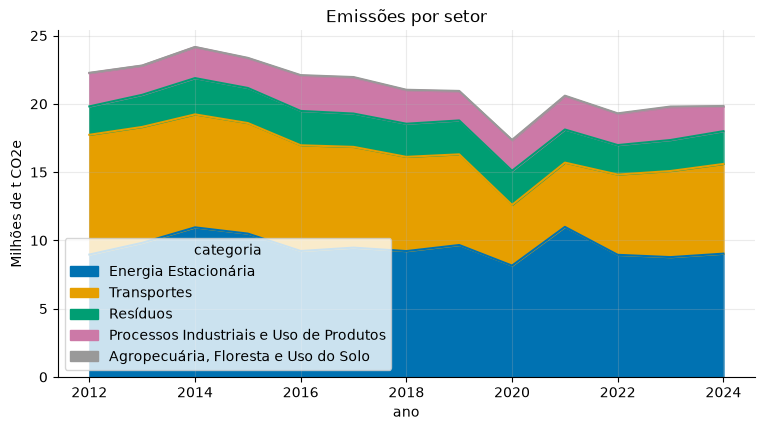

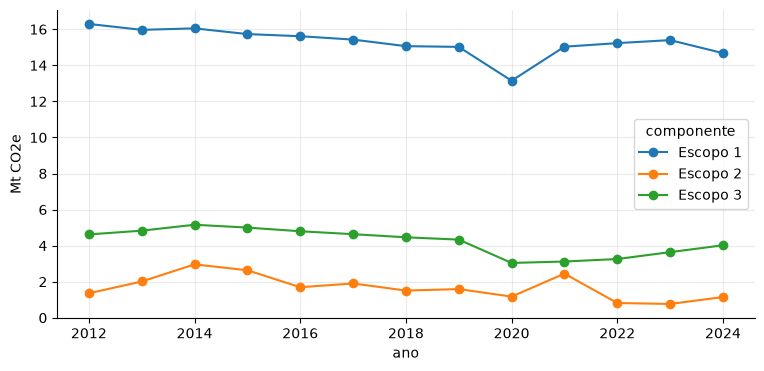

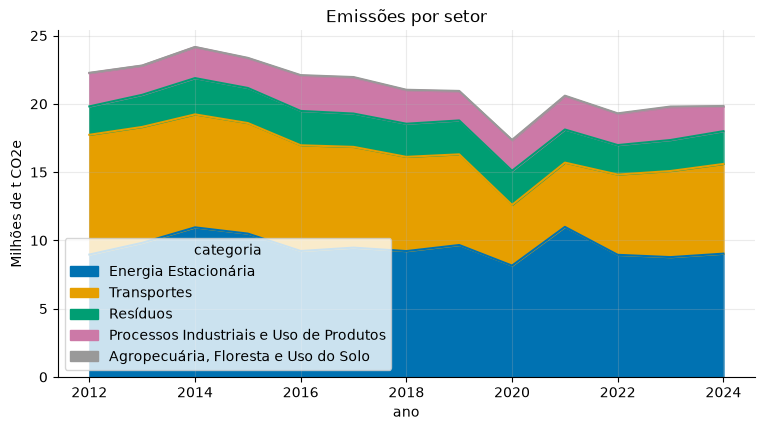

In [12]:
ax = (s/1e6).plot.area(figsize=(9,4.5), color=[analysis.COR_SETOR[c] for c in s.columns])
ax.set_ylabel("Milhões de t CO2e"); ax.set_title("Emissões por setor"); plt.show()

Coeficiente de variação por setor (desvio-padrão / média):

In [6]:
(s.std()/s.mean()*100).round(1).sort_values(ascending=False)

categoria
Agropecuária, Floresta e Uso do Solo       28.8
Transportes                                19.8
Processos Industriais e Uso de Produtos     9.7
Energia Estacionária                        9.0
Resíduos                                    6.6
dtype: float64

## 3. RQ2 — Escopos e o papel do Escopo 2

componente
Escopo 1     5.2
Escopo 2    40.2
Escopo 3    17.4
Total        8.7
dtype: float64
corr(Escopo 2, geração p/ SIN) = 0.67


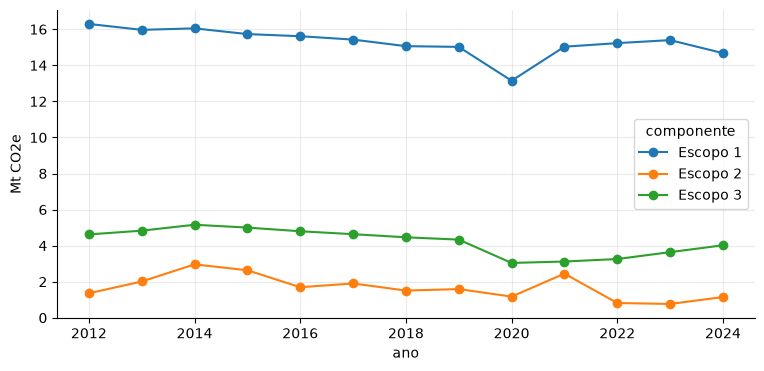

In [13]:
esc = analysis.tabela_total(df, "escopo")
print((esc.std()/esc.mean()*100).round(1))
sin = analysis.serie_sin(df)
print("corr(Escopo 2, geração p/ SIN) =", round(esc["Escopo 2"].corr(sin), 2))
(esc[["Escopo 1","Escopo 2","Escopo 3"]]/1e6).plot(marker="o", figsize=(9,4)); plt.ylabel("Mt CO2e"); plt.show()

## 4. RQ3 — Subsetores e gases

In [14]:
sub = analysis.tabela_subsetores(df)
delta = (sub[2024] - sub[2012]).sort_values()
print((delta.head(5)/1e6).round(2)); print((delta.tail(5)/1e6).round(2))
print("Soma das 3 maiores quedas (Mt):", round(delta.head(3).sum()/1e6, 2), "| variação líquida (Mt):", round(delta.sum()/1e6, 2))

categoria
Aéreo                     -1.21
Rodoviário                -0.92
Produção de ferro e aço   -0.66
Residencial               -0.16
Comercial                 -0.15
dtype: float64
categoria
Uso de óxido nitroso                                                0.04
Perdas comerciais de energia elétrica + outros não categorizados    0.07
Indústrias de manufatura e construção                               0.16
Indústrias de energia                                               0.19
Aterramento                                                         0.38
dtype: float64
Soma das 3 maiores quedas (Mt): -2.8 | variação líquida (Mt): -2.43


In [15]:
gas = analysis.tabela_total(df, "gas")
(gas[["CO2","CH4","N2O"]].div(gas["Total"], axis=0)*100).loc[[2012, 2018, 2024]].round(2)

componente,CO2,CH4,N2O
ano,,,
2012,89.01,9.32,1.67
2018,86.93,11.36,1.71
2024,86.17,11.95,1.88


## 5. Reprodução das figuras do artigo
`python -m src.analysis` regenera os PNGs em `docs/assets/`.